In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

#load the csv file
df = pd.read_csv("dry straight hair data/Extension_Dry_20mmmin_S.csv")
print(df)

      Record  Strain (%)  Stress (MPa)
0          1         0.0           0.1
1          1         0.0           0.0
2          1         0.0           0.0
3          1         0.0           0.0
4          1         0.0          -0.1
...      ...         ...           ...
2770      25         3.6          97.8
2771      25         3.7          99.7
2772      25         3.8         101.8
2773      25         3.9         103.4
2774      25         3.9         105.3

[2775 rows x 3 columns]


In [17]:
#Convert columns to numbers
df["Strain (%)"] = pd.to_numeric(df["Strain (%)"], errors='coerce')
df["Stress (MPa)"] = pd.to_numeric(df["Stress (MPa)"], errors='coerce')
df = df.dropna(subset=["Strain (%)", "Stress (MPa)"])  # Drop rows with NaN values in these columns

#Sort by strain
df = df.sort_values("Strain (%)")

#Check the data
print(df.head())
print(df.info())

    Record  Strain (%)  Stress (MPa)
13       1         0.0           0.1
12       1         0.0           0.0
11       1         0.0          -0.1
10       1         0.0          -0.1
9        1         0.0          -0.1
<class 'pandas.core.frame.DataFrame'>
Index: 2775 entries, 13 to 2774
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Record        2775 non-null   int64  
 1   Strain (%)    2775 non-null   float64
 2   Stress (MPa)  2775 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 86.7 KB
None


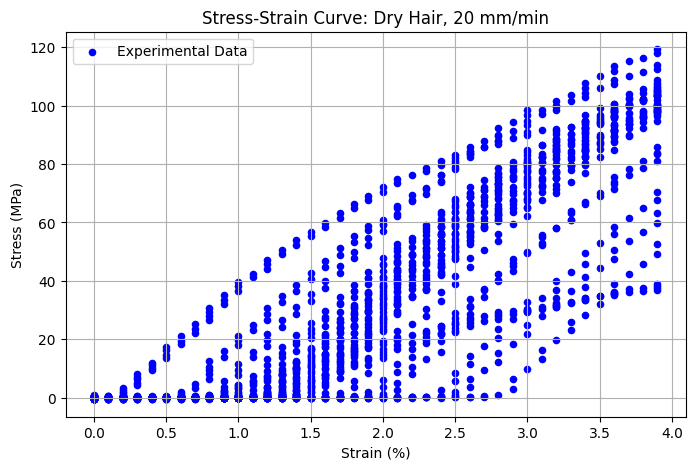

In [18]:
plt.figure(figsize=(8, 5)) #Raw stress-strain data
plt.scatter(df["Strain (%)"], df["Stress (MPa)"], s=20, label = "Experimental Data", color='blue')

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Stress-Strain Curve: Dry Hair, 20 mm/min")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
mean_df = (df.groupby("Strain (%)")["Stress (MPa)"].agg(['mean', 'std']).reset_index())
print(mean_df)

    Strain (%)       mean        std
0          0.0   0.009492   0.155498
1          0.1   0.007471   0.151682
2          0.2   0.085256   0.430874
3          0.3   0.274138   1.321601
4          0.4   0.426923   2.082392
5          0.5   0.673684   3.127714
6          0.6   0.770930   3.623936
7          0.7   1.205882   4.896873
8          0.8   1.707000   5.929165
9          0.9   2.141096   7.033784
10         1.0   3.216667   8.517058
11         1.1   3.679630   9.269821
12         1.2   5.583582  11.350899
13         1.3   6.759649  11.580277
14         1.4   9.482000  13.237249
15         1.5  11.948000  14.177810
16         1.6  14.890000  15.194833
17         1.7  18.348000  16.271413
18         1.8  21.774000  17.330612
19         1.9  25.348000  18.353538
20         2.0  29.036000  19.268328
21         2.1  33.248000  20.297584
22         2.2  34.944118  21.932571
23         2.3  41.065854  20.814918
24         2.4  43.368000  22.600690
25         2.5  47.700000  23.204882
2

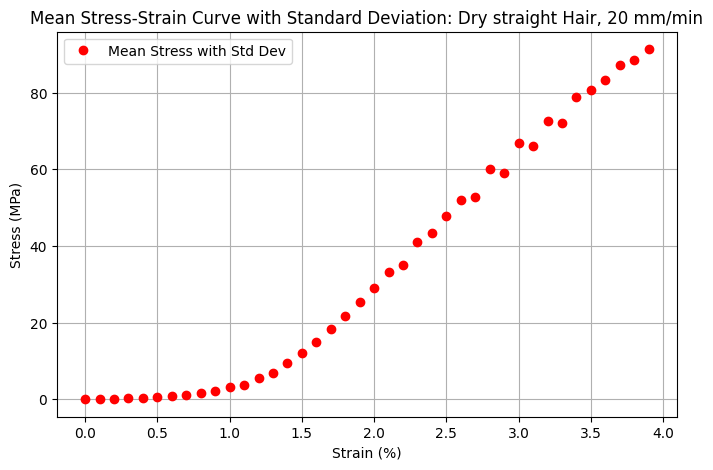

In [20]:
plt.figure(figsize=(8, 5)) 
plt.errorbar(mean_df["Strain (%)"], mean_df["mean"], fmt='o', label='Mean Stress with Std Dev', color='red', capsize=3)

plt.xlabel("Strain (%)")
plt.ylabel("Stress (MPa)")
plt.title("Mean Stress-Strain Curve with Standard Deviation: Dry straight Hair, 20 mm/min")
plt.legend()
plt.grid(True)
plt.show()